# NumPy 5: Ufuncs y agregaciones

_Autor: Milena Barrios Gallego_

Este notebook enseña a hacer una cuenta con todos los números de un array a la vez, sin bucles, y a resumir un array a lo largo del eje que elijamos. Con eso aparece la curva de luz de la estrella. Cubre:

1. Cuentas elemento a elemento
2. Resumir en un número: agregaciones
3. Elegir el eje: `axis`
4. La curva de luz

Este notebook asume que ya viste los de NumPy 1 a 4 (arrays, `np.load`, forma y ejes, indexación, copias y vistas).

## 0. Prerrequisitos

Para correr este notebook, asegúrate de haber creado el ambiente virtual de Python siguiendo las instrucciones del README del repositorio. Una vez creado, selecciona ese kernel en el notebook.

Los datos están en la carpeta `data/`, al lado de esta carpeta `notebooks/`.

Los gráficos se hacen con `plot_helpers`, que ya viene en el repo (ver el README), y no con matplotlib directamente: esta serie enseña NumPy, no a graficar.

Para instalar Python, el manejador de paquetes UV, los ambientes de Conda y configurar Visual Studio Code para correr Jupyter Notebooks, revisa estos recursos:

- [Cómo instalar Anaconda y Jupyter](https://youtu.be/YzOLOlH1jQk?si=2hFk6aAh8gCoMvuo)
- [Instalación de UV](https://youtu.be/TJor7z8g8FA?si=QT2XVKeC29dYyDts)
- [VS Code + Jupyter Notebooks](https://youtu.be/rL1usXq4bgE?si=2b5REnUzVBMDxWfF)

### Prompts de profundización

Al final de cada sección hay unas preguntas para que cada uno profundice más.

## 1. Cuentas elemento a elemento

Cargamos los tres archivos de la serie y las funciones para graficar.

In [24]:
import numpy as np
from plot_helpers import plot_frame, plot_light_curve

# I load the three data files of the series
cube = np.load("../data/flux_cube.npy")
time = np.load("../data/time.npy")
mask = np.load("../data/aperture_mask.npy")

Un array con un número: a cada píxel de la primera foto le restamos 80. Miramos los tres primeros píxeles de la fila 0, antes y después:

In [25]:
# I take the first photo and subtract 80 from every pixel, with no loop
frame = cube[0]
shifted = frame - 80

# I print the first three pixels of row 0, before and after
print(frame[0, :3])
print(shifted[0, :3])

[80.09261 80.61298 85.45614]
[0.09261322 0.6129837  5.4561386 ]


Un array con otro de la misma forma: la foto por la máscara, píxel con píxel. `True` cuenta como 1 y `False` como 0.

In [26]:
# I look at one row of the mask: it holds True and False values
print(mask[5])

# I multiply that row by 1 to see True as 1 and False as 0
print(mask[5] * 1)

[False False  True  True  True  True  True  True False False False]
[0 0 1 1 1 1 1 1 0 0 0]


(11, 11)


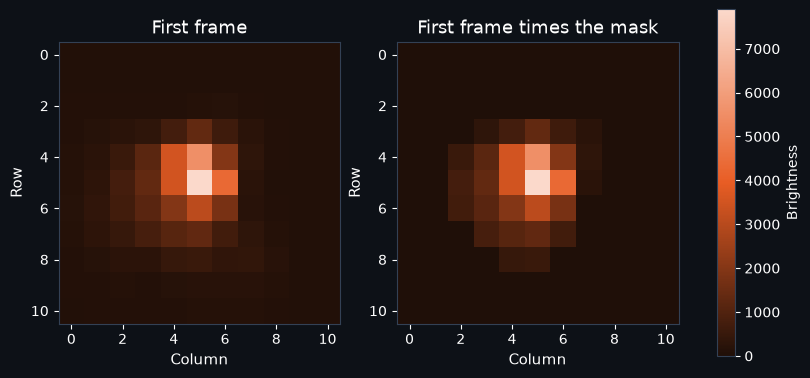

In [27]:
# I multiply the photo by the mask, pixel by pixel
star_only = frame * mask

print(star_only.shape)
plot_frame([frame, star_only], title=["First frame", "First frame times the mask"])

Al lado de la estrella, el fondo sale casi negro. Con `scale="sqrt"` se resaltan los valores bajos:

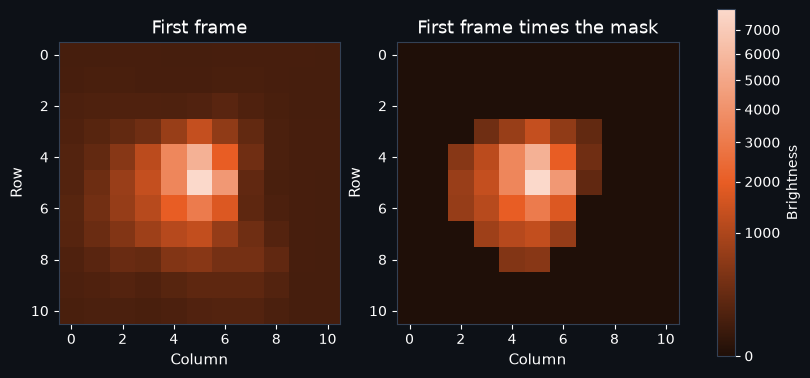

In [28]:
# I use a scale that highlights the low values
plot_frame([frame, star_only], title=["First frame", "First frame times the mask"], scale="sqrt")

Y con el contorno de la máscara encima:

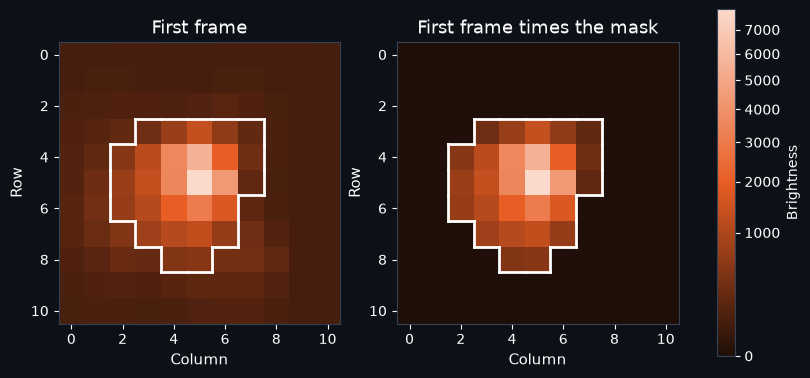

In [29]:
# I draw the outline of the mask on top
plot_frame(
    [frame, star_only],
    mask=mask,
    title=["First frame", "First frame times the mask"],
    scale="sqrt",
)

`np.abs` quita el signo de cada número. ¿Cuánto cambió cada píxel del recuadro de la estrella entre la primera y la segunda foto?

In [30]:
# I subtract two photos pixel by pixel and drop the sign of each result
change = np.abs(cube[1] - cube[0])

# I look at the 3 x 3 square around the star
print(change[4:7, 4:7])

[[67.24414  84.33057  54.453247]
 [15.523926 22.935059 62.550293]
 [34.79651  81.35449  90.03882 ]]


**Prompts de profundización:**

- `¿Qué es una ufunc en NumPy y qué operaciones lo son?`
- `¿Por qué en NumPy True se comporta como 1 y False como 0 al hacer cuentas?`
- `¿Qué diferencia hay entre arr - 80 y arr -= 80 en NumPy?`

## 2. Resumir en un número: agregaciones

`np.sum` ya lo conocemos. Otras funciones también resumen muchos números en uno: el promedio, el más grande y el más pequeño de la primera foto.

In [31]:
# I summarize the 121 pixels of the first photo in one number each time
print(np.mean(frame))
print(np.max(frame))
print(np.min(frame))

498.57812
7896.526
76.18285


El cambio total entre la primera y la segunda foto, con signo y sin signo:

In [32]:
# I add up the change with sign and without sign
print(np.sum(cube[1] - cube[0]))
print(np.sum(change))

-17.472878
1002.72125


**Prompts de profundización:**

- `¿Qué es una agregación en NumPy y cuáles son las más usadas?`
- `¿Cuándo conviene usar la mediana en vez del promedio para resumir datos?`
- `¿Qué diferencia hay entre np.sum(arr) y arr.sum() en NumPy?`

## 3. Elegir el eje: `axis`

La tabla de la estrella: una fila por foto, una columna por píxel. `axis` dice a lo largo de qué eje se resume; ese eje desaparece.

In [34]:
# I build the table of the star: one row per photo, one column per star pixel
table = cube[:, mask]

# I sum along axis 0 and along axis 1, and compare the shapes
print(np.sum(table, axis=0).shape)
print(np.sum(table, axis=1).shape)

(28,)
(1440,)


(11, 11)


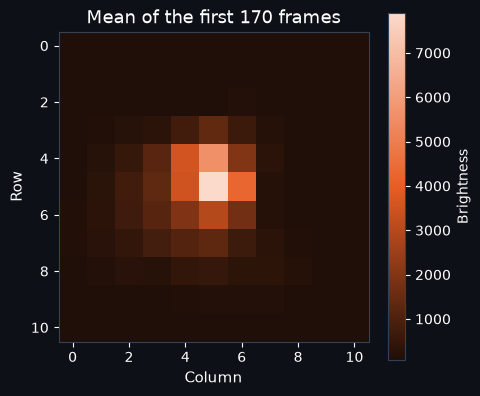

In [35]:
# I average the first 170 photos along axis 0: the photos disappear
mean_frame = np.mean(cube[:170], axis=0)

print(mean_frame.shape)
plot_frame(mean_frame, title="Mean of the first 170 frames")

Para quitar varios ejes a la vez, se pasan juntos:

In [36]:
# I remove only the rows, and then rows and columns together
print(np.mean(cube, axis=1).shape)
print(np.mean(cube, axis=(1, 2)).shape)
print(np.mean(cube, axis=(1, 2))[0])

(1440, 11)
(1440,)
498.57812


**Prompts de profundización:**

- `¿Cómo funciona el parámetro axis en las funciones de NumPy y cómo recordar qué eje desaparece?`
- `¿Qué hace keepdims=True en np.sum y para qué sirve?`
- `¿Cómo se resume una imagen a lo largo del tiempo en un video guardado como array?`

## 4. La curva de luz

Sumamos cada fila de la tabla de la estrella: el brillo de la estrella en cada foto.

In [37]:
# I sum each row of the table: the brightness of the star in each photo
light_curve = np.sum(table, axis=1)

print(light_curve[:3])

[48030.15  48024.062 48036.42 ]


Graficado contra el tiempo:

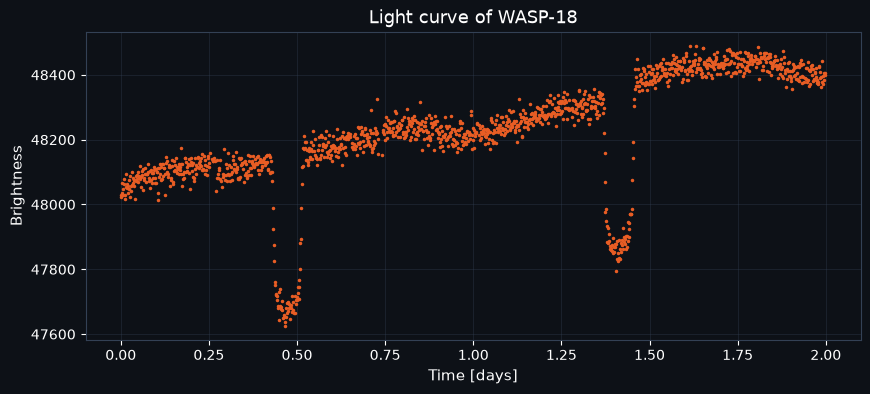

In [38]:
# I plot the brightness of the star against time
plot_light_curve(time, light_curve, title="Light curve of WASP-18")

**Prompts de profundización:**

- `¿Qué es una curva de luz y cómo se descubren planetas con el método de tránsitos?`
- `¿Por qué sumar varios píxeles reduce el ruido de una medición?`
- `¿Cómo se estima el tamaño de un planeta a partir de la profundidad de su tránsito?`

## 5. ¿Qué viene?

La curva sube porque el fondo del cielo sube. El píxel de la esquina casi solo tiene fondo: intentemos restárselo a cada foto.

In [39]:
# I take the corner pixel in every photo: it is mostly sky background
background = cube[:, 0, 0]

print(background.shape)

# I try to subtract it from every photo (this cell raises an error on purpose)
cube - background

(1440,)


ValueError: operands could not be broadcast together with shapes (1440,11,11) (1440,) 

## Referencias

- NumPy Developers. *NumPy documentation*. https://numpy.org/doc/stable/
- NumPy Developers. *Universal functions (ufunc)*. https://numpy.org/doc/stable/reference/ufuncs.html
- NumPy Developers. *numpy.sum*. https://numpy.org/doc/stable/reference/generated/numpy.sum.html

---

*Última actualización: noviembre 2026*